# LAB OVERVIEW

The goal of this lab is to measure the position an asteroids proper motion using 4 observations. The orbit of an asteroid can actually be fairly well constrained using only a few observations, but for this lab we are just going to measure its proper motion. 

In terms of the data reduction and analysis, we will break it up into a few steps:

1) Familiarize yourself with the data and how to obtain clean sky images (Today)

2) Find stars in your cleaned images and cross correlate them with a catelog (Jan 23)

3) Plate solve your images and compute asteroid positions (Jan 30)

In [1]:
#IMPORTS
import numpy as np
from astropy.io import fits
import matplotlib.pyplot as plt
import os
from glob import glob
import ta_funcs as ta

The first thing to do in this lab is become comfortable with all of different types of files and what they look like.

Let's take a look at the data provided in the google drive. 

https://drive.google.com/drive/folders/16T_1tjW3e-D5N0hxuAdCRYt_x0RZBj-u

In [2]:
"""
A function that returns all of the sky, flat, dark, and bias files for a given
observation folder
"""
def get_and_sort_files(folder, extension = 'fts'):

    files = [y for x in os.walk(folder) for y in glob(os.path.join(x[0], '*.' + extension))]

    asteroid_files = [f for f in files if "26Proserpina-" in f]
    flat_files = [f for f in files if "Flat" in f]
    dark_files = [f for f in files if "Dark" in f]
    bias_files = [f for f in files if "Bias" in f]

    asteroid_files.sort()
    flat_files.sort() 
    dark_files.sort() 
    bias_files.sort()
    
    return asteroid_files, flat_files, dark_files, bias_files  

In [3]:
folder = "../Asteroid_Lab/26Proserpina/"
obs = ["20120119", "20120120","20120122", "20120125"]
obs_num = 0

asteroid_files, flat_files, dark_files, bias_files = get_and_sort_files(folder + obs[obs_num])

print(asteroid_files)

['../Asteroid_Lab/26Proserpina/20120119/26Proserpina-S001-R001-C001-r.fts', '../Asteroid_Lab/26Proserpina/20120119/26Proserpina-S001-R001-C002-r.fts', '../Asteroid_Lab/26Proserpina/20120119/26Proserpina-S001-R001-C003-r.fts']


In [4]:
for i,f in enumerate(asteroid_files):
    header, img, center_of_field = ta.read_file(f, verbose=False, sky_image=True)
    exp = header["EXPOSURE"]
    index = f.index("26Proserpina-")
    temp = np.round(header["CCD-TEMP"],2)
    print(f"Sky Image '{f[index:]}' --- Exposure Time: {exp}s Temperature: {temp}")   

Sky Image '26Proserpina-S001-R001-C001-r.fts' --- Exposure Time: 60.0s Temperature: -25.22
Sky Image '26Proserpina-S001-R001-C002-r.fts' --- Exposure Time: 60.0s Temperature: -25.11
Sky Image '26Proserpina-S001-R001-C003-r.fts' --- Exposure Time: 60.0s Temperature: -25.12


In [5]:
for i,f in enumerate(dark_files):
    header, img, center_of_field = ta.read_file(f, verbose=False, sky_image=False)
    exp = header["EXPOSURE"]
    index = f.index("Dark")
    temp = np.round(header["CCD-TEMP"],2)
    print(f"Dark Image '{f[index:]}' --- Exposure Time: {exp}s Temperature: {temp}")   

Dark Image 'Dark-S001-R001-C001-B2.fts' --- Exposure Time: 120.0s Temperature: -25.1
Dark Image 'Dark-S001-R001-C002-B2.fts' --- Exposure Time: 120.0s Temperature: -25.16
Dark Image 'Dark-S001-R001-C003-B2.fts' --- Exposure Time: 120.0s Temperature: -25.22
Dark Image 'Dark-S001-R001-C004-B2.fts' --- Exposure Time: 120.0s Temperature: -25.3
Dark Image 'Dark-S001-R001-C005-B2.fts' --- Exposure Time: 120.0s Temperature: -25.33
Dark Image 'Dark-S001-R002-C001-B2.fts' --- Exposure Time: 30.0s Temperature: -25.29
Dark Image 'Dark-S001-R002-C002-B2.fts' --- Exposure Time: 30.0s Temperature: -25.29
Dark Image 'Dark-S001-R002-C003-B2.fts' --- Exposure Time: 30.0s Temperature: -25.27
Dark Image 'Dark-S001-R002-C004-B2.fts' --- Exposure Time: 30.0s Temperature: -25.24
Dark Image 'Dark-S001-R002-C005-B2.fts' --- Exposure Time: 30.0s Temperature: -25.04
Dark Image 'Dark-S001-R003-C001-B2.fts' --- Exposure Time: 60.0s Temperature: -25.02
Dark Image 'Dark-S001-R003-C002-B2.fts' --- Exposure Time: 60.

In [6]:
for i,f in enumerate(flat_files):
    header, img, center_of_field = ta.read_file(f, verbose=False, sky_image=False)
    exp = header["EXPOSURE"]
    index = f.index("AutoFlat-")
    temp = np.round(header["CCD-TEMP"],2)
    print(f"Flat Image '{f[index:]}' --- Exposure Time: {exp}s Temperature: {temp}")   

Flat Image 'AutoFlat-Dusk-r-Bin2-001.fts' --- Exposure Time: 1.75s Temperature: -4.7
Flat Image 'AutoFlat-Dusk-r-Bin2-002.fts' --- Exposure Time: 2.07s Temperature: -4.37
Flat Image 'AutoFlat-Dusk-r-Bin2-003.fts' --- Exposure Time: 2.21s Temperature: -3.96
Flat Image 'AutoFlat-Dusk-r-Bin2-004.fts' --- Exposure Time: 2.35s Temperature: -3.62
Flat Image 'AutoFlat-Dusk-r-Bin2-005.fts' --- Exposure Time: 2.5s Temperature: -3.21


Notice that the exposure time of the dark files is variable, we want to match the exposure time of our images so that we account for the correct amount of dark current.

In [7]:
dark_files_60s = [f for f in dark_files if "R003" in f]

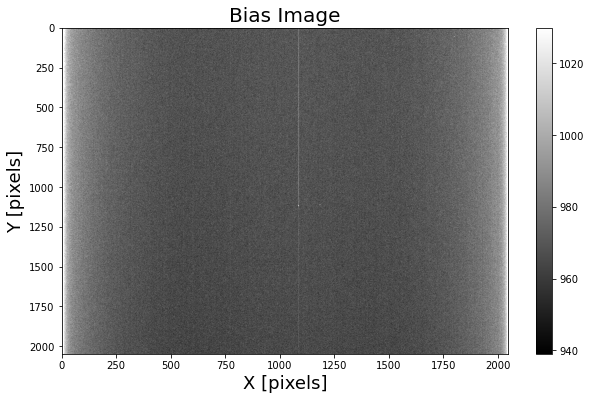

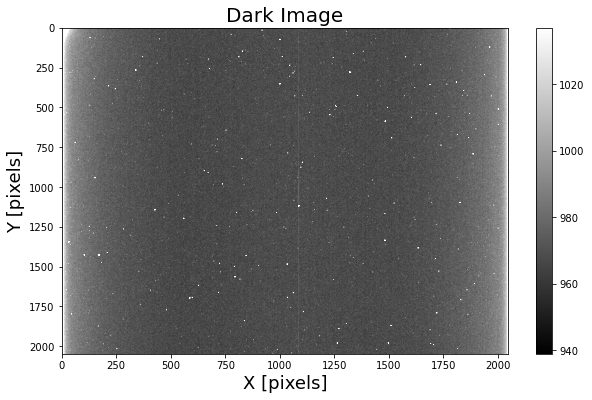

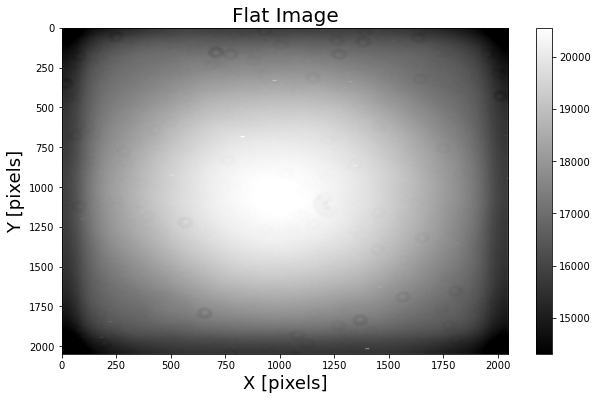

['05 24 07.53', '+26 58 50.5']


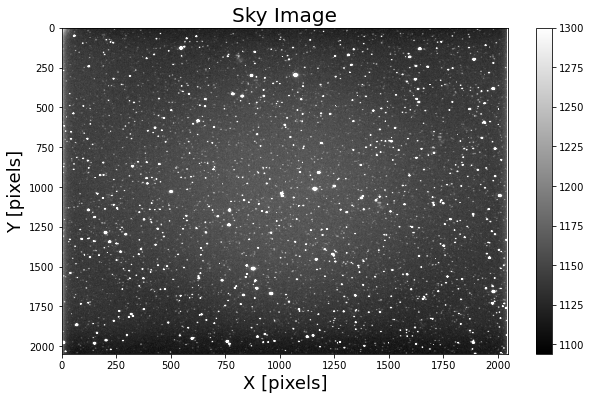

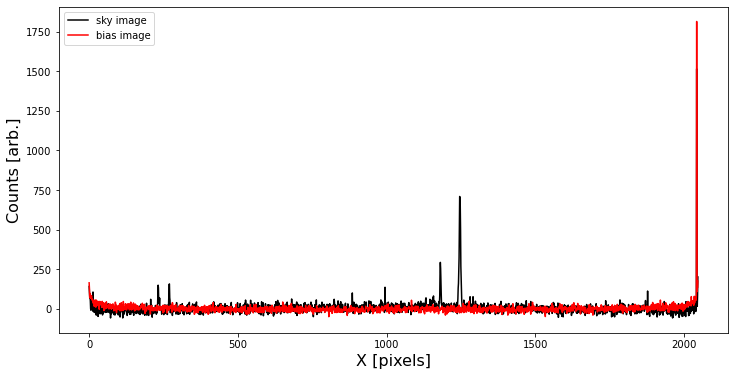

In [8]:
header, bias, center_of_field = ta.read_file(bias_files[0], verbose = False, sky_image=False)
ta.plot_image(bias, title = "Bias Image", log = False)
header, dark, center_of_field = ta.read_file(dark_files_60s[0], verbose = False, sky_image=False)
ta.plot_image(dark, title = "Dark Image", log = False)
header, flat, center_of_field = ta.read_file(flat_files[0], verbose = False, sky_image=False)
ta.plot_image(flat, title = "Flat Image", log = False)
header, img, center_of_field = ta.read_file(asteroid_files[0], verbose = False, sky_image=True)
print(center_of_field)

"""print(header)
TALK ABOUT IMAGE FLIPPING
"""
img = img[::-1,::-1]


ta.plot_image(img, title = "Sky Image", log = False)

plt.figure(figsize=(12,6))
plt.plot(img[1000,:] - np.median(img[1000,:] ), label = 'sky image', color = 'k')
plt.plot(bias[1000,:] - np.median(bias[1000,:]), label = 'bias image', color = 'r')
plt.xlabel("X [pixels]" , size = 16)
plt.ylabel("Counts [arb.]" , size = 16)
plt.legend()
plt.show()


Now that we have oriented ourselves with what the files look like and what they are, we can average all of them together to get te best images for the image cleaning.

In [9]:
median_bias = ta.get_bias_from_files(bias_files)

median_flat = ta.get_flat_from_files(flat_files, median_bias)

median_dark = ta.get_dark_from_files(dark_files_60s, median_bias)

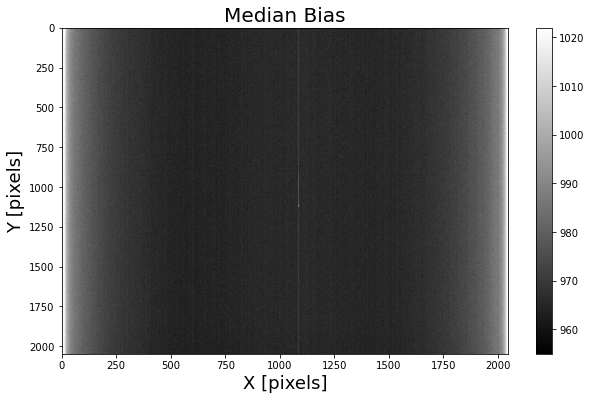

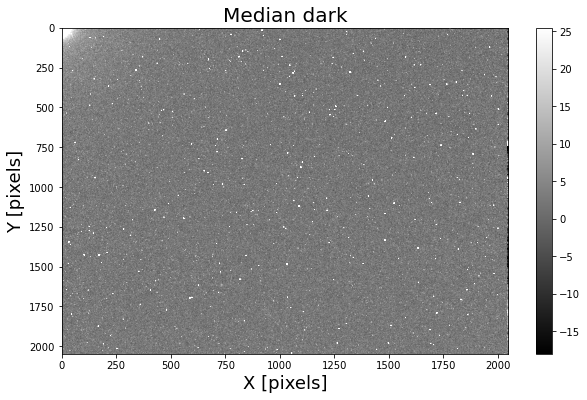

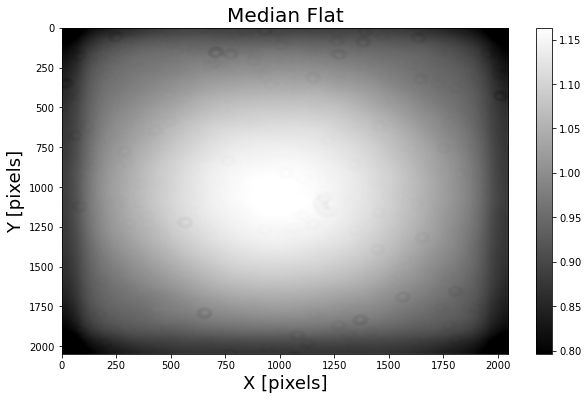

In [10]:
ta.plot_image(median_bias, title = "Median Bias", log = False)
ta.plot_image(median_dark, title = "Median dark", log = False)
ta.plot_image(median_flat, title =  "Median Flat", log = False)

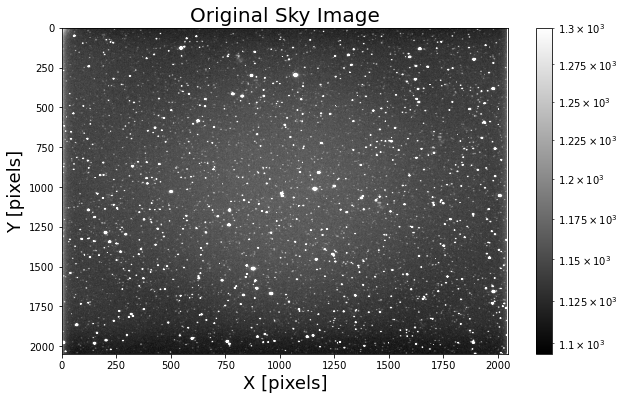

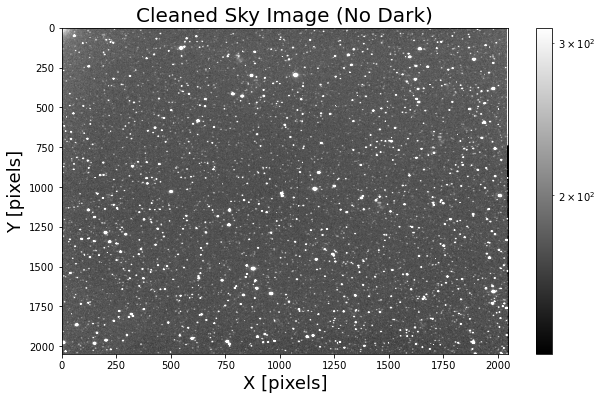

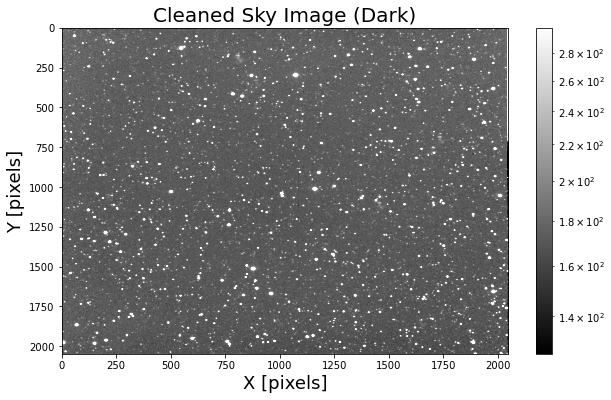

In [11]:
clean_img_no_dark = (img - median_bias )/(median_flat)
clean_img_dark = (img - median_bias - median_dark)/(median_flat)
ta.plot_image(img, title =  "Original Sky Image", log = True)
ta.plot_image(clean_img_no_dark, title =  "Cleaned Sky Image (No Dark)", log = True)
ta.plot_image(clean_img_dark, title =  "Cleaned Sky Image (Dark)", log = True)

In [12]:
"""
NEXT TIME: FINDING STARS IN YOUR IMAGE AND MATCHING THEM TO THE CATALOG
"""

'\nNEXT TIME: FINDING STARS IN YOUR IMAGE AND MATCHING THEM TO THE CATALOG\n'